# Case Study I – Sprint 3: Optimization and Explainability

In Sprint 2 we compared 6 models and 2 cleaning versions. The winner was:

**Cleaning A (strict) + Association rules + targeted logistic regression** → validation EMR = **86.70%**, test EMR = 96.30%.

In this notebook we only use the winner. We try to improve it by changing the 3 settings that were chosen by hand in Sprint 2:

| Setting | Sprint 2 value | What it does |
|---|---|---|
| `n_targets` | 15 | How many hard BIL items get their own logistic regression |
| `n_features` | 8 | How many CRM options each logistic regression looks at |
| `C` | 0.5 | How careful the logistic regression is (small = more careful) |

**Plan:**

· 1–4. Load the data and copy the functions we need from Sprint 2
· 5. Same validation split as Sprint 2 (80% / 20%, seed 42)
· 6. Data check: billing errors in both directions, and Cleaning C (does removing suspicious bills help?)
· 7. Try one setting (first check: Sprint 2 values must give 86.70%)
· 8. Try 48 settings and rank them
· 9. Confirm the best setting with 5 rounds (GroupKFold), to make sure it is not luck
· 10. Final model on all training data, one final check against `solution.csv`
· 11–18. Explainability: how the model decides, where it fails, one customer explained, limits

Files needed in the same folder: `train.csv`, `test.csv`, `solution.csv`.

### 1. Libraries and settings

In [1]:
import time

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42  # same seed as Sprint 2, so results can be compared

### 2. Load the data

Same as Sprint 2: every 0/1 column is loaded as `uint8` to save memory.

In [2]:
id_col = "MSISDN"


def binary_column_types(file_name):
    # Read only the header, then load every 0/1 column as uint8 and the ID as text
    columns = pd.read_csv(file_name, nrows=0).columns
    return {c: (str if c == id_col else np.uint8) for c in columns}


train = pd.read_csv("train.csv", dtype=binary_column_types("train.csv"))
test = pd.read_csv("test.csv", dtype=binary_column_types("test.csv"))
print(f"Train: {train.shape[0]:,} rows | Test: {test.shape[0]:,} rows")

Train: 187,442 rows | Test: 97,100 rows


In [3]:
crm_cols = [c for c in train.columns if c.startswith("CRM")]
bil_cols = [c for c in train.columns if c.startswith("BIL")]
assert list(test.columns) == [id_col] + crm_cols
print("CRM features:", len(crm_cols), "| Billing targets:", len(bil_cols))

CRM features: 745 | Billing targets: 731


### 3. Functions copied from Sprint 2

These functions are **the same** as in Sprint 2 (sections 4, 5 and 7). Nothing new here.

In [4]:
PROFILE_GROUPS = ["CRM_SUBSCRIBER_TYPE", "CRM_SUBSCRIBER_STATUS",
                  "BIL_SUBSCRIBER_TYPE", "BIL_SUBSCRIBER_STATUS"]


def row_ids(data, columns):
    # One ID number per row: same 0/1 values -> same ID
    return pd.util.hash_pandas_object(data[columns], index=False).to_numpy()


def broken_profile_mask(data, groups):
    # True for rows that do not have exactly one "1" in each group of columns
    correct = np.ones(len(data), dtype=bool)
    for group in groups:
        group_cols = [c for c in data.columns if c.startswith(group)]
        correct &= data[group_cols].sum(axis=1).to_numpy() == 1
    return ~correct

In [5]:
def phi_matrix(features, targets, weights, chunk_size=8192):
    # Weighted phi coefficient between every CRM column and every BIL column
    weights = np.asarray(weights, dtype=np.float64)
    total = weights.sum()
    feature_sums = weights @ features
    target_sums = weights @ targets
    cross = np.zeros((features.shape[1], targets.shape[1]), dtype=np.float64)
    for start in range(0, len(features), chunk_size):
        stop = start + chunk_size
        x_chunk = features[start:stop].astype(np.float64) * weights[start:stop, None]
        cross += x_chunk.T @ targets[start:stop].astype(np.float64)
    numerator = total * cross - feature_sums[:, None] * target_sums[None, :]
    feature_var = feature_sums * (total - feature_sums)
    target_var = target_sums * (total - target_sums)
    denominator = np.sqrt(feature_var[:, None] * target_var[None, :])
    return np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)

In [6]:
def majority_vote(rows, feature_cols, target_cols, drop_ties):
    # Keep one row per subscription: the bill that most customers with it have
    pairs = pd.DataFrame({
        "crm_id": row_ids(rows, feature_cols),
        "bil_id": row_ids(rows, target_cols),
        "row": np.arange(len(rows)),
    })
    counts = (
        pairs.groupby(["crm_id", "bil_id"], sort=False)
        .agg(weight=("row", "size"), first_row=("row", "first"))
        .reset_index()
    )
    counts = counts.sort_values("weight", ascending=False, kind="stable")
    if drop_ties:
        top = counts.groupby("crm_id")["weight"].transform("max")
        winners_per_subscription = (counts["weight"] == top).groupby(counts["crm_id"]).transform("sum")
        counts = counts[winners_per_subscription == 1]
    winners = counts.drop_duplicates("crm_id", keep="first")
    cleaned = rows.iloc[winners["first_row"].to_numpy()][feature_cols + target_cols].reset_index(drop=True)
    return cleaned, winners["weight"].to_numpy(dtype=np.float64)


def clean_version_a(rows):
    # Cleaning A (winner): drop constant CRM columns, broken profiles and tied subscriptions
    features = [c for c in crm_cols if rows[c].min() != rows[c].max()]
    rows = rows[~broken_profile_mask(rows, PROFILE_GROUPS)]
    cleaned, weights = majority_vote(rows, features, bil_cols, drop_ties=True)
    return cleaned, weights, features

In [7]:
def association_predict(rows, weights, features, predict_rows):
    # For each BIL item: copy (or invert) the CRM option with the strongest phi association
    x_train = rows[features].to_numpy(dtype=np.uint8)
    y_train = rows[bil_cols].to_numpy(dtype=np.uint8)
    phi = phi_matrix(x_train, y_train, weights)
    best_feature = np.abs(phi).argmax(axis=0)
    best_phi = phi[best_feature, np.arange(len(bil_cols))]

    predictions = predict_rows[features].to_numpy(dtype=np.uint8)[:, best_feature].copy()
    negative = best_phi < 0
    predictions[:, negative] = 1 - predictions[:, negative]

    # Items with no association: use the weighted majority value of the item
    no_association = np.abs(best_phi) <= 1e-12
    target_majority = ((weights @ y_train) >= weights.sum() / 2).astype(np.uint8)
    predictions[:, no_association] = target_majority[no_association]
    return predictions


def find_hard_targets(raw_rows, n_targets, cleaning):
    # Inner grouped split: find the BIL items where association rules make the most errors
    groups = row_ids(raw_rows, crm_cols)
    inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE + 1)
    inner_fit, inner_check = next(inner.split(raw_rows, groups=groups))
    inner_rows, inner_weights, inner_features = cleaning(raw_rows.iloc[inner_fit])
    check_rows = raw_rows.iloc[inner_check]
    inner_predictions = association_predict(inner_rows, inner_weights, inner_features, check_rows)
    error_rate = (inner_predictions != check_rows[bil_cols].to_numpy(dtype=np.uint8)).mean(axis=0)
    return [bil_cols[i] for i in np.argsort(error_rate)[-n_targets:][::-1]]


def score_predictions(predictions, truth):
    errors = np.asarray(predictions) != truth
    return {
        "EMR": np.all(~errors, axis=1).mean(),
        "Hamming loss": errors.mean(),
        "Mean wrong items per customer": errors.sum(axis=1).mean(),
    }

### 4. The winning model, with its 3 settings as inputs

The model is split in two steps, so trying many settings is fast:

· **`prepare`** does the slow part **once**: the cleaning (Cleaning A unless we say otherwise), association rules, and the list of the 40 hardest BIL items (from hardest to easiest).
· **`predict_with_settings`** does the fast part: for the first `n_targets` hard items, it trains a small logistic regression with `n_features` CRM options and strength `C`.

With `n_targets=15, n_features=8, C=0.5` this gives exactly the Sprint 2 model. Taking the first 15 items of the "top 40" list gives the same 15 items as Sprint 2.

In [8]:
MAX_TARGETS = 40  # the largest n_targets we will try


def prepare(raw_rows, predict_rows, cleaning=clean_version_a):
    # Slow part, done once: clean, association rules, hard items and their phi
    rows, weights, features = cleaning(raw_rows)
    base_predictions = association_predict(rows, weights, features, predict_rows)
    hard_ranking = find_hard_targets(raw_rows, MAX_TARGETS, cleaning)
    x_train = rows[features].to_numpy(dtype=np.uint8)
    phi_hard = phi_matrix(x_train, rows[hard_ranking].to_numpy(dtype=np.uint8), weights)
    return {"rows": rows, "weights": weights, "features": features, "predict_rows": predict_rows,
            "base_predictions": base_predictions, "hard_ranking": hard_ranking, "phi_hard": phi_hard}

In [9]:
def predict_with_settings(prep, n_targets, n_features, C):
    # Fast part: logistic regression for the first n_targets hard items
    predictions = prep["base_predictions"].copy()
    rows, features = prep["rows"], prep["features"]
    for position, target in enumerate(prep["hard_ranking"][:n_targets]):
        y_target = rows[target].to_numpy(dtype=np.uint8)
        if np.unique(y_target).size < 2:
            continue
        # The n_features CRM options most associated with this BIL item
        selected = [features[i] for i in np.argsort(np.abs(prep["phi_hard"][:, position]))[-n_features:]]
        model = LogisticRegression(C=C, solver="liblinear", max_iter=300, random_state=RANDOM_STATE)
        model.fit(rows[selected].to_numpy(dtype=np.uint8), y_target, sample_weight=prep["weights"])
        predictions[:, bil_cols.index(target)] = model.predict(prep["predict_rows"][selected].to_numpy(dtype=np.uint8))
    return predictions

### 5. Same validation split as Sprint 2

80% to learn, 20% as the practice exam. Same seed (42) and same groups, so the 20% are **the same customers** as in Sprint 2.

In [10]:
train_crm_id = row_ids(train, crm_cols)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
fit_idx, validation_idx = next(splitter.split(train, groups=train_crm_id))
fit_part = train.iloc[fit_idx].reset_index(drop=True)
validation = train.iloc[validation_idx].reset_index(drop=True)
y_validation = validation[bil_cols].to_numpy(dtype=np.uint8)
print(f"Training part: {len(fit_part):,} rows | Validation: {len(validation):,} rows")

Training part: 153,380 rows | Validation: 34,062 rows


In [11]:
# Slow part, done once for sections 7 and 8
start = time.time()
prep_validation = prepare(fit_part, validation)
print(f"Prepared in {time.time() - start:.0f}s")

Prepared in 14s


### 6. Data check: billing errors in both directions

The system has errors: the same CRM with different bills, and the opposite, the same bill with different CRM. We check both on the full training set (this is only a description, nothing is trained here).

In [12]:
# One ID per subscription and one ID per bill, for every customer
pairs = pd.DataFrame({"crm_id": train_crm_id, "bil_id": row_ids(train, bil_cols)})

# Direction 1: same subscription, different bills (fixed by the majority vote)
bills_per_crm = pairs.groupby("crm_id")["bil_id"].nunique()
print("Subscriptions with 2+ different bills:", (bills_per_crm > 1).sum())

# Direction 2: same bill, different subscriptions
crms_per_bill = pairs.groupby("bil_id")["crm_id"].nunique()
print("Bills shared by 2+ different subscriptions:", (crms_per_bill > 1).sum())

Subscriptions with 2+ different bills: 617
Bills shared by 2+ different subscriptions: 873


Direction 2 is **not always an error**. If two subscriptions differ only in an option that does not change the bill (a free option), the same bill is correct. It is suspicious only when they differ in an option that **should** change the bill: an option with a high phi (≥ 0.9) with some BIL item.

In [13]:
# For each bill: which CRM columns change between its subscriptions?
keep = ~pairs.duplicated().to_numpy()
subs = train.loc[keep, crm_cols].copy()
subs["bil_id"] = pairs.loc[keep, "bil_id"].to_numpy()
changes = subs.groupby("bil_id")[crm_cols].nunique() > 1

# How important is each CRM column for the bill? (strongest phi with any BIL item)
train_phi = phi_matrix(train[crm_cols].to_numpy(), train[bil_cols].to_numpy(), np.ones(len(train)))
check = pd.DataFrame({"times_it_changes": changes.sum(),
                      "best_phi": np.abs(train_phi).max(axis=1)}, index=crm_cols)
check.sort_values("times_it_changes", ascending=False).head(15)

,times_it_changes,best_phi
CRM_1539_PACK,533,0.624364
CRM_1536_PACK,532,0.624484
CRM_1661_PACK,117,0.052008
CRM_SUBSCRIBER_STATUS_ORIG_Block_2_Way,50,0.954844
CRM_SUBSCRIBER_STATUS_ORIG_Active,37,0.988765
CRM_1553_PACK,28,0.992824
CRM_1569_PACK,28,0.297308
CRM_SUBSCRIBER_STATUS_ORIG_Block_1_Way,20,0.984789
CRM_1552_PACK,13,0.949231
CRM_1563_PACK,7,0.971693


In [14]:
# Suspicious: the CRM column changes inside a bill AND strongly affects the bill
suspicious_cols = check[(check["times_it_changes"] > 0) & (check["best_phi"] >= 0.9)].index.tolist()
suspicious_bills = changes[suspicious_cols].any(axis=1)
print(f"Suspicious bills: {suspicious_bills.sum()} of {len(changes):,} ({suspicious_bills.mean():.2%})")

# CRM_1536 and CRM_1539 change the most: do they always change together?
both = changes["CRM_1536_PACK"] & changes["CRM_1539_PACK"]
print("Bills where CRM_1536 and CRM_1539 both change:", both.sum())

Suspicious bills: 177 of 67,201 (0.26%)
Bills where CRM_1536 and CRM_1539 both change: 532


#### Cleaning C: remove the suspicious bills

Cleaning C = Cleaning A, then remove the bills where a strong CRM column (phi ≥ 0.9) changes between subscriptions. We do not know which customer of the group is wrong, so we remove the whole group. The phi is recalculated **inside** the function, only with the learning rows, so the practice exam is not used.

In [15]:
def clean_version_c(rows, phi_limit=0.9):
    # Start from Cleaning A
    cleaned, weights, features = clean_version_a(rows)

    # CRM columns that strongly affect the bill
    phi = phi_matrix(cleaned[features].to_numpy(), cleaned[bil_cols].to_numpy(), weights)
    strong_cols = [f for f, p in zip(features, np.abs(phi).max(axis=1)) if p >= phi_limit]

    # Bills where a strong column changes between subscriptions: drop them
    bill_id = row_ids(cleaned, bil_cols)
    changes_c = cleaned[strong_cols].groupby(bill_id).nunique() > 1
    bad_bills = changes_c.index[changes_c.any(axis=1)]
    keep_rows = ~np.isin(bill_id, bad_bills)
    return cleaned[keep_rows].reset_index(drop=True), weights[keep_rows], features

In [16]:
# Same model (Sprint 2 settings), same practice exam: Cleaning A vs Cleaning C
prep_c = prepare(fit_part, validation, clean_version_c)
print(f"Training rows: Cleaning A = {len(prep_validation['rows']):,} | Cleaning C = {len(prep_c['rows']):,}")

emr_a = score_predictions(predict_with_settings(prep_validation, 15, 8, 0.5), y_validation)["EMR"]
emr_c = score_predictions(predict_with_settings(prep_c, 15, 8, 0.5), y_validation)["EMR"]
pd.DataFrame({"Cleaning": ["A – strict", "C – no suspicious bills"],
              "EMR (%)": [round(emr_a * 100, 2), round(emr_c * 100, 2)],
              "Extra correct customers vs A": [0, round((emr_c - emr_a) * len(validation))]})

Training rows: Cleaning A = 50,053 | Cleaning C = 49,884


,Cleaning,EMR (%),Extra correct customers vs A
0,A – strict,86.7,0
1,C – no suspicious bills,86.7,1


**Decision:** if Cleaning C does not clearly improve the EMR (a few customers out of 34,062 is not a real gain), we keep **Cleaning A**, which is simpler. The rest of the notebook uses Cleaning A.

### 7. Try one setting

Change the 3 values and run the cell to see the EMR.

**First check:** with the Sprint 2 values (15, 8, 0.5) the EMR must be **86.70%**. If it is, the copy of the model is correct.

In [17]:
N_TARGETS = 15
N_FEATURES = 8
C_VALUE = 0.5

predictions = predict_with_settings(prep_validation, N_TARGETS, N_FEATURES, C_VALUE)
scores = score_predictions(predictions, y_validation)
print(f"n_targets={N_TARGETS}, n_features={N_FEATURES}, C={C_VALUE}")
print(f"EMR = {scores['EMR']:.2%} | Mean wrong items per customer = {scores['Mean wrong items per customer']:.3f}")

n_targets=15, n_features=8, C=0.5
EMR = 86.70% | Mean wrong items per customer = 1.795


### 8. Try 48 settings and rank them

4 values of `n_targets` × 4 values of `n_features` × 3 values of `C` = 48 settings. Same practice exam for all of them.

In [18]:
N_TARGETS_VALUES = [10, 15, 25, 40]
N_FEATURES_VALUES = [4, 8, 12, 20]
C_VALUES = [0.1, 0.5, 1.0]

In [19]:
start = time.time()
grid_results = []
for n_targets in N_TARGETS_VALUES:
    for n_features in N_FEATURES_VALUES:
        for c_value in C_VALUES:
            predictions = predict_with_settings(prep_validation, n_targets, n_features, c_value)
            scores = score_predictions(predictions, y_validation)
            grid_results.append({"n_targets": n_targets, "n_features": n_features, "C": c_value, **scores})
print(f"48 settings tried in {time.time() - start:.0f}s")

48 settings tried in 66s


In [20]:
# Best first: highest EMR, and if equal, lowest Hamming loss
grid_table = pd.DataFrame(grid_results).sort_values(["EMR", "Hamming loss"], ascending=[False, True]).reset_index(drop=True)
grid_table["EMR (%)"] = (grid_table["EMR"] * 100).round(2)
grid_table["Extra correct customers vs Sprint 2"] = (
    (grid_table["EMR"] - grid_table.query("n_targets == 15 and n_features == 8 and C == 0.5")["EMR"].iloc[0])
    * len(validation)
).round().astype(int)
grid_table[["n_targets", "n_features", "C", "EMR (%)", "Extra correct customers vs Sprint 2",
            "Mean wrong items per customer"]].head(15)

,n_targets,n_features,C,EMR (%),Extra correct customers vs Sprint 2,Mean wrong items per customer
0,10,20,0.5,86.73,11,1.795872
1,10,20,1.0,86.73,10,1.796048
2,15,20,0.5,86.72,8,1.794081
3,15,20,1.0,86.72,7,1.794346
4,10,8,0.5,86.71,3,1.796929
5,10,12,0.5,86.71,3,1.796929
6,10,12,1.0,86.71,3,1.796958
7,10,8,1.0,86.71,3,1.796988
8,25,20,0.5,86.71,2,1.787329
9,25,20,1.0,86.70,1,1.787857


In [21]:
best = grid_table.iloc[0]
BEST_SETTING = (int(best["n_targets"]), int(best["n_features"]), float(best["C"]))
SPRINT2_SETTING = (15, 8, 0.5)
print("Sprint 2 setting:", SPRINT2_SETTING)
print("Best setting:    ", BEST_SETTING, f"(validation EMR = {best['EMR']:.2%})")

Sprint 2 setting: (15, 8, 0.5)
Best setting:     (10, 20, 0.5) (validation EMR = 86.73%)


### 9. Confirm the best setting with 5 rounds (GroupKFold)

One practice exam can be lucky. Here we cut the **whole training set** into 5 parts. Customers with the same subscription always stay in the same part.

In each round, one part is the practice exam and the other 4 are used to learn. We compare the **Sprint 2 setting** and the **best setting** in the same 5 rounds.

**Rule:** we keep the best setting only if it wins in **at least 4 of the 5 rounds** and has a **higher average EMR**. Otherwise we keep the Sprint 2 setting.

This cell is the slowest of the notebook (the slow part runs 5 times).

In [22]:
folds = GroupKFold(n_splits=5)
fold_results = []
start = time.time()
for round_number, (learn_idx, exam_idx) in enumerate(folds.split(train, groups=train_crm_id), start=1):
    learn_part = train.iloc[learn_idx].reset_index(drop=True)
    exam_part = train.iloc[exam_idx].reset_index(drop=True)
    y_exam = exam_part[bil_cols].to_numpy(dtype=np.uint8)
    prep_round = prepare(learn_part, exam_part)

    old_emr = score_predictions(predict_with_settings(prep_round, *SPRINT2_SETTING), y_exam)["EMR"]
    new_emr = score_predictions(predict_with_settings(prep_round, *BEST_SETTING), y_exam)["EMR"]
    fold_results.append({"Round": round_number, "Exam customers": len(exam_part),
                         "EMR Sprint 2 (%)": round(old_emr * 100, 2), "EMR best (%)": round(new_emr * 100, 2),
                         "Best wins": new_emr > old_emr})
    print(f"Round {round_number} done ({time.time() - start:.0f}s)")

fold_table = pd.DataFrame(fold_results)
fold_table

Round 1 done (15s)
Round 2 done (31s)
Round 3 done (46s)
Round 4 done (61s)
Round 5 done (76s)


,Round,Exam customers,EMR Sprint 2 (%),EMR best (%),Best wins
0,1,37489,87.72,87.88,True
1,2,37489,88.38,88.40,True
2,3,37488,87.76,87.78,True
3,4,37488,87.70,87.78,True
4,5,37488,87.34,87.33,False


In [23]:
wins = int(fold_table["Best wins"].sum())
old_mean = fold_table["EMR Sprint 2 (%)"].mean()
new_mean = fold_table["EMR best (%)"].mean()
print(f"Best setting wins in {wins} of 5 rounds")
print(f"Average EMR: Sprint 2 = {old_mean:.2f}% | best = {new_mean:.2f}%")

if BEST_SETTING != SPRINT2_SETTING and wins >= 4 and new_mean > old_mean:
    FINAL_SETTING = BEST_SETTING
    print("Decision: the improvement is real. We use the best setting.")
else:
    FINAL_SETTING = SPRINT2_SETTING
    print("Decision: no reliable improvement. We keep the Sprint 2 setting.")
print("Final setting:", FINAL_SETTING)

Best setting wins in 4 of 5 rounds
Average EMR: Sprint 2 = 87.78% | best = 87.83%
Decision: the improvement is real. We use the best setting.
Final setting: (10, 20, 0.5)


### 10. Final model and one final check against `solution.csv`

Train on **all** the training data with the final setting, predict the test customers, and save `submission_sprint3.csv` (the Sprint 2 file is not overwritten). Then, only once, compare with `solution.csv`.

In [24]:
start = time.time()
prep_final = prepare(train, test)
final_predictions = predict_with_settings(prep_final, *FINAL_SETTING)

submission = pd.DataFrame({
    id_col: test[id_col].to_numpy(),
    "Bill_Conf": ["".join(row.astype(str)) for row in final_predictions],
})
assert submission["Bill_Conf"].str.len().eq(len(bil_cols)).all()
submission.to_csv("submission_sprint3.csv", index=False)
print(f"Saved submission_sprint3.csv: {submission.shape} | Time: {time.time() - start:.0f}s")

Saved submission_sprint3.csv: (97100, 2) | Time: 37s


In [25]:
solution = pd.read_csv("solution.csv", dtype=str)
aligned = submission.set_index(id_col).reindex(solution[id_col])
predicted_bits = np.array([list(bill) for bill in aligned["Bill_Conf"]], dtype=np.uint8)
true_bits = np.array([list(bill) for bill in solution["Bill_Conf"]], dtype=np.uint8)

test_scores = score_predictions(predicted_bits, true_bits)
print("Final setting:", FINAL_SETTING)
print(f"Test EMR = {test_scores['EMR']:.2%} (Sprint 2: 96.30%)")
print(f"Mean wrong items per customer = {test_scores['Mean wrong items per customer']:.3f} (Sprint 2: 0.059)")

Final setting: (10, 20, 0.5)
Test EMR = 96.33% (Sprint 2: 96.30%)
Mean wrong items per customer = 0.059 (Sprint 2: 0.059)


# Part 2 – Explainability

**Goal:** show *why* the model predicts each bill, in a way a person can check.

Our model is a **transparent model** (a "glass box"): every bill item is decided by a rule we can read, like *"if the customer has CRM_1533, then BIL_3934 = 1"*. Tools like **SHAP** or **LIME** are made for **black-box** models (neural networks, boosting), where the decision cannot be read directly. For our model they would only give an approximation of rules we can already read exactly, so we do not use them.

We explain the model at two levels:

| Level | Question | Section |
|---|---|---|
| Global | How does the model decide, in general? | 12–15 |
| Errors | Where does it fail, and why? | 16 |
| Local | Why did *this* customer get *this* bill? | 17 |
| Limits | What the explanations cannot tell us | 18 |

Global explanations use the **final model** (trained on all the training data, section 10). Errors and the customer examples use the **practice exam** (validation), because there we know the real bills. `solution.csv` is not used again.

### 11. Chart library

In [26]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

BLUE = "#2a6fdb"     # rules / "push to 1" / correct 1
ORANGE = "#c8601e"   # logistic / "push to 0" / wrong
GRAY = "#d5d9e0"     # correct 0
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 12. How the model works

For each of the 731 BIL items, the model takes one of two paths. Most items follow a single rule. The few hard items get a small logistic regression.

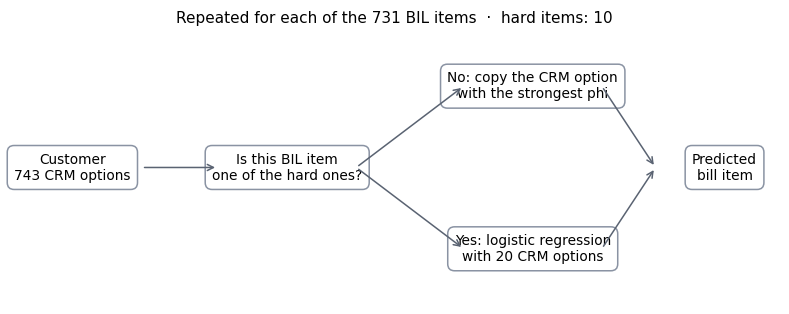

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axis("off")
boxes = {
    "crm": (0.08, 0.5, "Customer\n743 CRM options"),
    "question": (0.36, 0.5, "Is this BIL item\none of the hard ones?"),
    "rule": (0.68, 0.8, "No: copy the CRM option\nwith the strongest phi"),
    "logit": (0.68, 0.2, f"Yes: logistic regression\nwith {FINAL_SETTING[1]} CRM options"),
    "bill": (0.93, 0.5, "Predicted\nbill item"),
}
for x, y, text in boxes.values():
    ax.text(x, y, text, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#8a93a3"))
arrows = [("crm", "question"), ("question", "rule"), ("question", "logit"), ("rule", "bill"), ("logit", "bill")]
for start, end in arrows:
    (x1, y1, _), (x2, y2, _) = boxes[start], boxes[end]
    ax.annotate("", xy=(x2 - 0.09, y2), xytext=(x1 + 0.09, y1), arrowprops=dict(arrowstyle="->", color="#5a6372"))
ax.set_title(f"Repeated for each of the {len(bil_cols)} BIL items  ·  hard items: {FINAL_SETTING[0]}", fontsize=10)
plt.show()

### 13. The billing manual: which CRM option decides each BIL item

For every BIL item we list the CRM option with the strongest phi (from the final model).
· **copy**: the BIL item is 1 when the customer has the option (phi > 0).
· **invert**: the BIL item is 1 when the customer does **not** have the option (phi < 0).
· **majority value**: no CRM option is linked to the item, so it always gets its most common value.

In [29]:
def rule_table(prep, n_targets):
    # For each BIL item: the CRM option that decides it, and how strong the link is (phi)
    rows, weights, features = prep["rows"], prep["weights"], prep["features"]
    phi = phi_matrix(rows[features].to_numpy(dtype=np.uint8), rows[bil_cols].to_numpy(dtype=np.uint8), weights)
    best = np.abs(phi).argmax(axis=0)
    best_phi = phi[best, np.arange(len(bil_cols))]

    table = pd.DataFrame({"BIL item": bil_cols, "Decided by": [features[i] for i in best], "phi": best_phi})
    table["Rule"] = np.where(best_phi >= 0, "copy", "invert")
    no_link = np.abs(best_phi) <= 1e-12
    table.loc[no_link, "Decided by"] = "(none)"
    table.loc[no_link, "Rule"] = "majority value"
    table["Uses logistic"] = table["BIL item"].isin(prep["hard_ranking"][:n_targets])
    return table


manual = rule_table(prep_final, FINAL_SETTING[0])
manual.sort_values("phi", key=abs, ascending=False).head(10)

,BIL item,Decided by,phi,Rule,Uses logistic
204,BIL_SUBSCRIBER_TYPE_ORIG_Postpaid,CRM_SUBSCRIBER_TYPE_ORIG_Postpaid,0.999692,copy,False
195,BIL_SUBSCRIBER_STATUS_ORIG_Barring,CRM_SUBSCRIBER_STATUS_ORIG_Barring,0.999679,copy,False
205,BIL_SUBSCRIBER_TYPE_ORIG_Prepaid,CRM_SUBSCRIBER_TYPE_ORIG_Postpaid,-0.999453,invert,False
202,BIL_SUBSCRIBER_STATUS_ORIG_Suspend,CRM_SUBSCRIBER_STATUS_ORIG_Suspend,0.998167,copy,False
85,BIL_3933_PACK,CRM_1542_PACK,0.996850,copy,False
79,BIL_3927_PACK,CRM_1541_PACK,0.996807,copy,False
86,BIL_3934_PACK,CRM_1533_PACK,0.996806,copy,False
196,BIL_SUBSCRIBER_STATUS_ORIG_Block_1_Way,CRM_SUBSCRIBER_STATUS_ORIG_Block_1_Way,0.996676,copy,True
8,BIL_3745_PACK,CRM_2087_PACK,0.996665,copy,False
7,BIL_3744_PACK,CRM_2088_PACK,0.996660,copy,False


In [30]:
# Summary: how strong are the rules?
strength = pd.cut(manual["phi"].abs().clip(upper=1), bins=[-0.01, 0.0001, 0.5, 0.9, 0.99, 1.0],
                  labels=["no link", "weak (< 0.5)", "medium (0.5–0.9)", "strong (0.9–0.99)", "almost perfect (≥ 0.99)"])
summary = strength.value_counts().reindex(strength.cat.categories).rename("BIL items").to_frame()
summary["Share (%)"] = (summary["BIL items"] / len(manual) * 100).round(1)
print("Rule types:", manual["Rule"].value_counts().to_dict())
print("BIL items that use logistic regression:", int(manual["Uses logistic"].sum()))
summary

Rule types: {'copy': 729, 'invert': 2}
BIL items that use logistic regression: 10


,BIL items,Share (%)
no link,0,0.0
weak (< 0.5),455,62.2
medium (0.5–0.9),159,21.8
strong (0.9–0.99),83,11.4
almost perfect (≥ 0.99),34,4.7


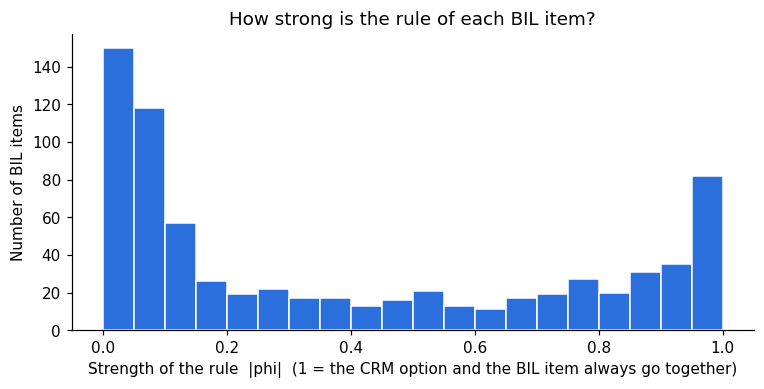

In [41]:
# Chart: how strong is the rule of each BIL item?
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(manual["phi"].abs().clip(upper=1), bins=20, range=(0, 1), color=BLUE, edgecolor="white")
ax.set_xlabel("Strength of the rule  |phi|  (1 = the CRM option and the BIL item always go together)")
ax.set_ylabel("Number of BIL items")
ax.set_title("How strong is the rule of each BIL item?")
plt.show()

### 14. The most influential CRM options

Some CRM options decide **several** BIL items. This is our version of "feature importance": the options the billing depends on most.

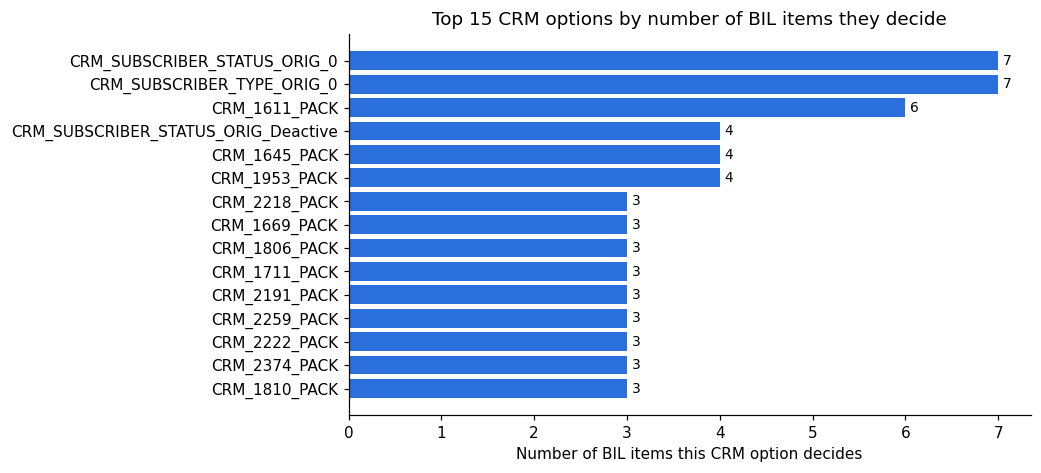

In [32]:
influence = manual[manual["Decided by"] != "(none)"]["Decided by"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(influence.index[::-1], influence.values[::-1], color=BLUE)
for y, value in enumerate(influence.values[::-1]):
    ax.text(value + 0.05, y, str(value), va="center", fontsize=9)
ax.set_xlabel("Number of BIL items this CRM option decides")
ax.set_title("Top 15 CRM options by number of BIL items they decide")
plt.show()

### 15. The hard items: how the logistic regression decides

For each hard BIL item, the logistic regression looks at a few CRM options at once. Each option gets a **coefficient**:
· **positive** (blue): having the option **pushes the item to 1**
· **negative** (orange): having the option **pushes the item to 0**
· bigger bar = stronger push

In [33]:
def fit_hard_model(prep, target, n_features, c_value):
    # Same steps as predict_with_settings, for one hard BIL item, returning the model
    position = prep["hard_ranking"].index(target)
    selected = [prep["features"][i] for i in np.argsort(np.abs(prep["phi_hard"][:, position]))[-n_features:]]
    y_target = prep["rows"][target].to_numpy(dtype=np.uint8)
    model = LogisticRegression(C=c_value, solver="liblinear", max_iter=300, random_state=RANDOM_STATE)
    model.fit(prep["rows"][selected].to_numpy(dtype=np.uint8), y_target, sample_weight=prep["weights"])
    return pd.Series(model.coef_[0], index=selected).sort_values()


hard_items = [t for t in prep_final["hard_ranking"][:FINAL_SETTING[0]] if prep_final["rows"][t].nunique() == 2]
print("Hard BIL items (hardest first):", hard_items)

Hard BIL items (hardest first): ['BIL_3940_PACK', 'BIL_3952_PACK', 'BIL_3803_PACK', 'BIL_SUBSCRIBER_STATUS_ORIG_Block_2_Way', 'BIL_SUBSCRIBER_STATUS_ORIG_Active', 'BIL_3762_PACK', 'BIL_SUBSCRIBER_STATUS_ORIG_Block_1_Way', 'BIL_4380_PACK', 'BIL_3742_PACK', 'BIL_4149_PACK']


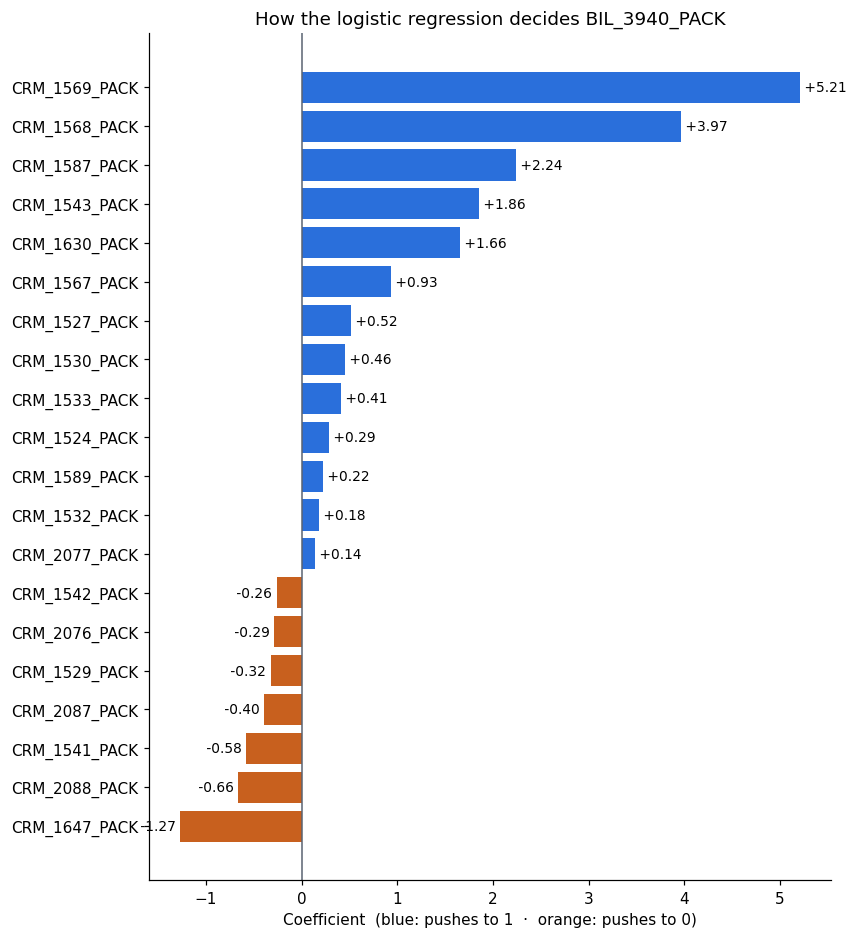

In [34]:
# Chart: the coefficients of the hardest item
coefficients = fit_hard_model(prep_final, hard_items[0], FINAL_SETTING[1], FINAL_SETTING[2])
colors = [BLUE if c > 0 else ORANGE for c in coefficients]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(coefficients) + 1))
ax.barh(coefficients.index, coefficients.values, color=colors)
ax.axvline(0, color="#5a6372", linewidth=1)
for y, value in enumerate(coefficients.values):
    ax.text(value, y, f" {value:+.2f} ", va="center", ha="left" if value > 0 else "right", fontsize=9)
ax.set_xlabel("Coefficient  (blue: pushes to 1  ·  orange: pushes to 0)")
ax.set_title(f"How the logistic regression decides {hard_items[0]}")
plt.show()

In [35]:
# Table: for every hard item, the option that pushes most to 1 and most to 0
hard_rows = []
for target in hard_items:
    coef = fit_hard_model(prep_final, target, FINAL_SETTING[1], FINAL_SETTING[2])
    to_one = f"{coef.index[-1]} ({coef.iloc[-1]:+.2f})" if coef.iloc[-1] > 0 else "none"
    to_zero = f"{coef.index[0]} ({coef.iloc[0]:+.2f})" if coef.iloc[0] < 0 else "none"
    hard_rows.append({"Hard BIL item": target, "Pushes most to 1": to_one, "Pushes most to 0": to_zero})
pd.DataFrame(hard_rows)

,Hard BIL item,Pushes most to 1,Pushes most to 0
0,BIL_3940_PACK,CRM_1569_PACK (+5.21),CRM_1647_PACK (-1.27)
1,BIL_3952_PACK,CRM_1598_PACK (+9.20),CRM_2087_PACK (-1.49)
2,BIL_3803_PACK,CRM_2205_PACK (+3.99),none
3,BIL_SUBSCRIBER_STATUS_ORIG_Block_2_Way,CRM_SUBSCRIBER_STATUS_ORIG_Block_2_Way (+9.98),CRM_SUBSCRIBER_STATUS_ORIG_Active (-3.07)
4,BIL_SUBSCRIBER_STATUS_ORIG_Active,CRM_SUBSCRIBER_STATUS_ORIG_Active (+11.23),CRM_SUBSCRIBER_STATUS_ORIG_Block_1_Way (-5.18)
5,BIL_3762_PACK,CRM_1553_PACK (+11.00),CRM_SUBSCRIBER_TYPE_ORIG_Postpaid (-3.19)
6,BIL_SUBSCRIBER_STATUS_ORIG_Block_1_Way,CRM_SUBSCRIBER_STATUS_ORIG_Block_1_Way (+11.35),CRM_SUBSCRIBER_STATUS_ORIG_Active (-2.67)
7,BIL_4380_PACK,CRM_1894_PACK (+1.98),none
8,BIL_3742_PACK,CRM_2093_PACK (+10.13),CRM_1542_PACK (-1.69)
9,BIL_4149_PACK,CRM_1759_PACK (+2.27),none


### 16. Where does the model fail?

On the practice exam (validation), with the final setting. Remember: the practice exam uses the original bills, which contain billing errors, so some "model errors" are in fact wrong bills in the data.

In [36]:
val_predictions = predict_with_settings(prep_validation, *FINAL_SETTING)
val_errors = val_predictions != y_validation
wrong_per_customer = val_errors.sum(axis=1)
print(f"Validation EMR = {(wrong_per_customer == 0).mean():.2%}")

Validation EMR = 86.73%


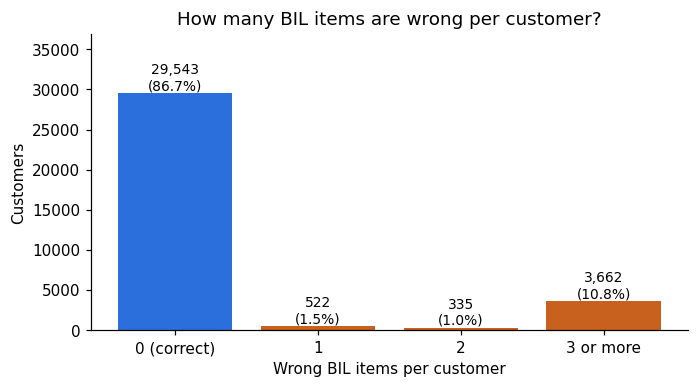

In [42]:
# Chart: how many items wrong per customer?
groups = pd.Series(np.minimum(wrong_per_customer, 3)).value_counts().reindex([0, 1, 2, 3], fill_value=0)
labels = ["0 (correct)", "1", "2", "3 or more"]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(labels, groups.values, color=[BLUE, ORANGE, ORANGE, ORANGE])
for x, value in enumerate(groups.values):
    ax.text(x, value, f"{value:,}\n({value / len(validation):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Wrong BIL items per customer")
ax.set_ylabel("Customers")
ax.set_title("How many BIL items are wrong per customer?")
ax.set_ylim(0, groups.max() * 1.25)
plt.show()

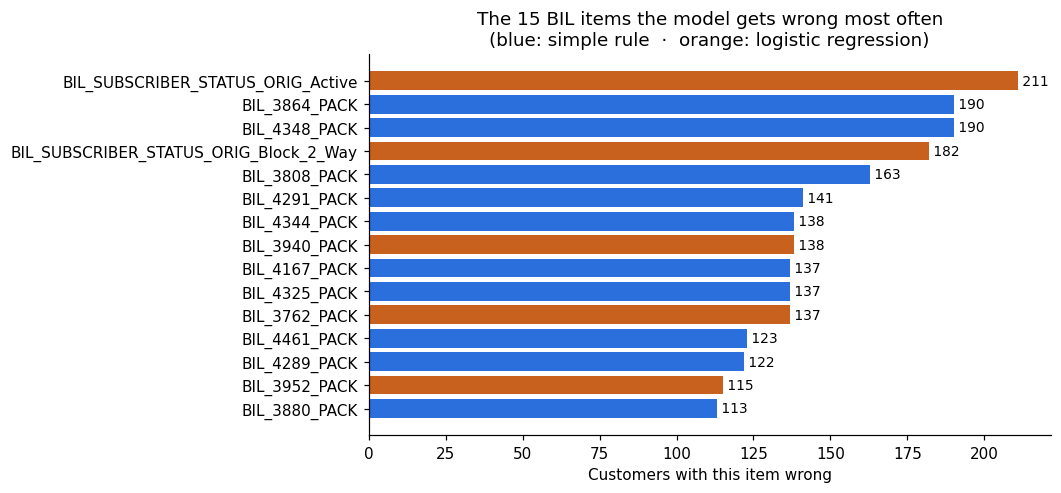

These 15 items (of 731) cause 3.7% of all wrong items.


In [38]:
# Chart: the 15 BIL items with the most errors
errors_per_item = pd.Series(val_errors.sum(axis=0), index=bil_cols).sort_values(ascending=False).head(15)
uses_logistic = manual.set_index("BIL item").loc[errors_per_item.index, "Uses logistic"]
colors = [ORANGE if flag else BLUE for flag in uses_logistic]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(errors_per_item.index[::-1], errors_per_item.values[::-1], color=colors[::-1])
for y, value in enumerate(errors_per_item.values[::-1]):
    ax.text(value, y, f" {value:,}", va="center", fontsize=9)
ax.set_xlabel("Customers with this item wrong")
ax.set_title("The 15 BIL items the model gets wrong most often\n(blue: simple rule  ·  orange: logistic regression)")
plt.show()

share = errors_per_item.sum() / val_errors.sum()
print(f"These 15 items (of {len(bil_cols)}) cause {share:.1%} of all wrong items.")

### 17. One customer explained

Each bill is drawn as a grid of 731 squares (17 rows × 43 columns): **gray** = item correctly predicted as 0, **blue** = item correctly predicted as 1, **orange** = wrong item. One orange square is enough for the customer to count as wrong in the EMR.

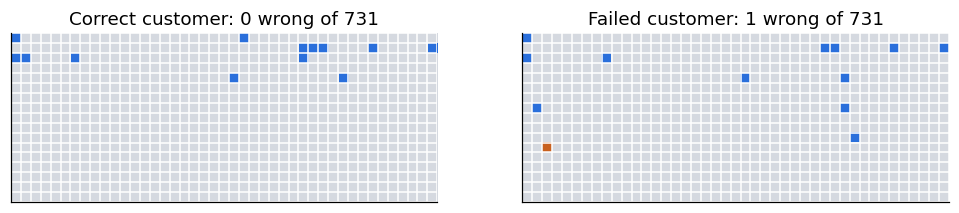

In [39]:
correct_customers = np.flatnonzero(wrong_per_customer == 0)
failed_customers = np.flatnonzero(wrong_per_customer == 1)
if len(failed_customers) == 0:
    failed_customers = np.flatnonzero(wrong_per_customer > 0)
customer_ok, customer_bad = correct_customers[0], failed_customers[0]


def bill_grid(customer):
    # 0 = correct 0, 1 = correct 1, 2 = wrong
    codes = np.where(val_errors[customer], 2, val_predictions[customer])
    return codes.reshape(17, 43)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
grid_colors = ListedColormap([GRAY, BLUE, ORANGE])
for ax, customer, title in [(axes[0], customer_ok, "Correct customer"), (axes[1], customer_bad, "Failed customer")]:
    ax.imshow(bill_grid(customer), cmap=grid_colors, vmin=0, vmax=2)
    ax.set_xticks(np.arange(-0.5, 43, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 17, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{title}: {val_errors[customer].sum()} wrong of 731")
plt.show()

In [40]:
def explain_customer(customer):
    # Every BIL item predicted as 1 or wrong, with the rule that decided it
    rules = rule_table(prep_validation, FINAL_SETTING[0]).set_index("BIL item")
    rows = []
    for j, item in enumerate(bil_cols):
        if val_predictions[customer, j] == 0 and not val_errors[customer, j]:
            continue
        rule = rules.loc[item]
        option = rule["Decided by"]
        rows.append({
            "BIL item": item,
            "Predicted": int(val_predictions[customer, j]),
            "Real": int(y_validation[customer, j]),
            "Result": "WRONG" if val_errors[customer, j] else "ok",
            "Decided by": "logistic regression" if rule["Uses logistic"] else f"{option} ({rule['Rule']})",
            "phi": round(rule["phi"], 3),
            "Customer has the option": "" if rule["Uses logistic"] or option == "(none)" else int(validation.loc[customer, option]),
        })
    return pd.DataFrame(rows)


print("Failed customer: items predicted as 1, and the wrong item")
explain_customer(customer_bad)

Failed customer: items predicted as 1, and the wrong item


,BIL item,Predicted,Real,Result,Decided by,phi,Customer has the option
0,BIL_BUSINESS_LINE_ORIG_Mobile,1,1,ok,CRM_SUBSCRIBER_STATUS_ORIG_Deactive (invert),-0.098,0
1,BIL_3921_PACK,1,1,ok,CRM_1529_PACK (copy),0.997,1
2,BIL_3922_PACK,1,1,ok,CRM_1532_PACK (copy),0.997,1
3,BIL_3928_PACK,1,1,ok,CRM_1564_PACK (copy),0.986,1
4,BIL_3933_PACK,1,1,ok,CRM_1533_PACK (copy),0.997,1
5,BIL_3934_PACK,1,1,ok,CRM_1533_PACK (copy),0.997,1
6,BIL_3944_PACK,1,1,ok,logistic regression,0.986,
7,BIL_SUBSCRIBER_STATUS_ORIG_Active,1,1,ok,logistic regression,0.995,
8,BIL_SUBSCRIBER_TYPE_ORIG_Postpaid,1,1,ok,CRM_SUBSCRIBER_TYPE_ORIG_Postpaid (copy),1.000,1
9,BIL_4077_PACK,1,1,ok,CRM_1726_PACK (copy),0.623,1


**How to read it:** each row is one BIL item of this customer. *Decided by* is the rule the model used. For the WRONG row, compare *Predicted* and *Real*: when the rule is almost perfect (phi close to 1), a wrong item often means this customer's bill does not follow the usual billing rule, which can be a billing error in the data and not a model error.

### 18. Limits of these explanations

· **Phi shows that two things appear together, not that one causes the other.** The rules describe how the company bills; they do not prove why.
· **One rule per item.** Most BIL items are decided by a single CRM option. Items that depend on combinations of options are covered only for the hard items (logistic regression).
· **Noisy labels.** The training and validation bills contain billing errors (Section 6). Some "errors" in Section 16 are wrong bills in the data, which is one reason validation EMR (≈86.7%) is lower than test EMR (96.3%).
· **The billing manual is useful for the company.** A customer whose bill breaks an almost perfect rule (phi ≥ 0.99) is a good candidate for a billing audit.